In [4]:
import setuptools
import os
import pandas as pd
from tdc.multi_pred import DDI
from tdc.utils import get_label_map
from rdkit import Chem

# Klasörleri garantiye alalım
os.makedirs('../data/raw', exist_ok=True)
os.makedirs('../data/interim', exist_ok=True)
os.makedirs('../figs', exist_ok=True)
os.makedirs('../docs', exist_ok=True)

# 1. TDC DrugBank DDI verisini resmi kaynaktan çekelim
print("TDC DrugBank verisi indiriliyor...")
data = DDI(name='DrugBank')
df = data.get_data()

# 2. Ham veriyi data/raw/ altına tek seferlik kaydedelim
df.to_csv('../data/raw/tdc_drugbank_ddi.csv', index=False)
print(f"Toplam satır (çift) sayısı: {len(df):,}")

# 3. 86 etkileşim tipinin açıklamalarını çekip kaydedelim
label_map = get_label_map(name='DrugBank', task='DDI')
df_labels = pd.DataFrame(list(label_map.items()), columns=['tip_id', 'aciklama'])
df_labels.to_csv('../data/interim/drugbank_tip_aciklama.csv', index=False)
print("86 tip açıklaması interim klasörüne kaydedildi.")

# 4. SMILES'ı RDKit ile okunamayan ilaçları tespit edelim
smiles_list = pd.concat([df['Drug1'], df['Drug2']]).dropna().unique()
hatali_smiles = [s for s in smiles_list if Chem.MolFromSmiles(s) is None]

print(f"Toplam benzersiz ilaç sayısı: {len(smiles_list):,}")
print(f"RDKit ile okunamayan hatalı SMILES sayısı: {len(hatali_smiles)}")

Downloading...


TDC DrugBank verisi indiriliyor...


100%|██████████| 44.4M/44.4M [00:01<00:00, 23.2MiB/s]
Loading...
Done!


Toplam satır (çift) sayısı: 191,808
86 tip açıklaması interim klasörüne kaydedildi.


[16:46:30] SMILES Parse Error: syntax error while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[16:46:30] SMILES Parse Error: Failed parsing SMILES 'OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1' for input: 'OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1'


Toplam benzersiz ilaç sayısı: 1,706
RDKit ile okunamayan hatalı SMILES sayısı: 1


In [3]:
%pip install "setuptools<70"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 894.6/894.6 kB 27.8 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.0.0
    Uninstalling setuptools-84.0.0:
      Successfully uninstalled setuptools-84.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.14.1 requires setuptools>=77.0.3, but you have setuptools 69.5.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


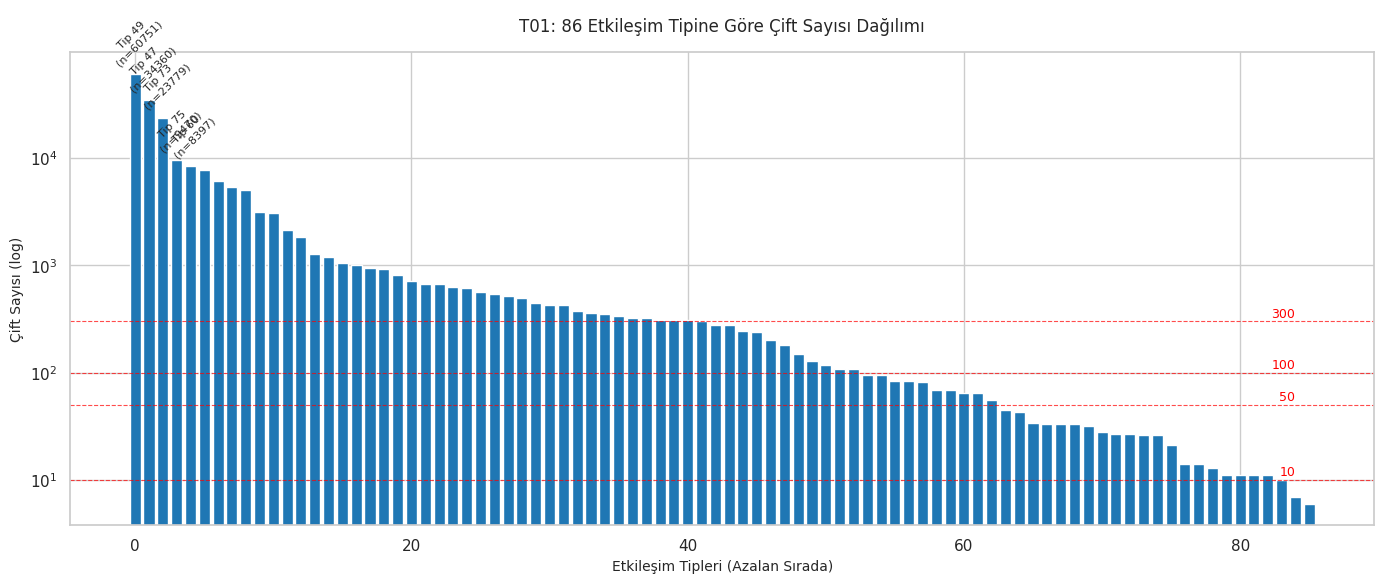

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. 86 tipin frekanslarını azalan sırada hesaplayalım
tip_sayilari = df['Y'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))

# Çubuk grafik çizimi
ax.bar(range(len(tip_sayilari)), tip_sayilari.values, color='#1f77b4', width=0.8)

# 2. Kurallar: Y ekseni logaritmik, 10, 50, 100 ve 300 seviyelerine yatay kesikli çizgiler
ax.set_yscale('log')
for cizgi in [10, 50, 100, 300]:
    ax.axhline(y=cizgi, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.text(len(tip_sayilari) - 2, cizgi * 1.1, f'{cizgi}', color='red', fontsize=9, ha='right')

# 3. En sık ilk 5 tip için açıklama etiketi
for i in range(5):
    tip_id = tip_sayilari.index[i]
    sayi = tip_sayilari.values[i]
    aciklama = label_map.get(tip_id, f"Tip {tip_id}")
    kisa_aciklama = (aciklama[:25] + '..') if len(aciklama) > 25 else aciklama
    ax.text(i, sayi * 1.15, f"Tip {tip_id}\n(n={sayi})", ha='center', va='bottom', fontsize=8, rotation=45)

ax.set_title("T01: 86 Etkileşim Tipine Göre Çift Sayısı Dağılımı", fontsize=12, pad=15)
ax.set_xlabel("Etkileşim Tipleri (Azalan Sırada)", fontsize=10)
ax.set_ylabel("Çift Sayısı (log)", fontsize=10)

plt.tight_layout()
# Grafiği 300 dpi olarak figs klasörüne kaydet
plt.savefig('../figs/T01_tip_dagilimi.png', dpi=300)
plt.show()

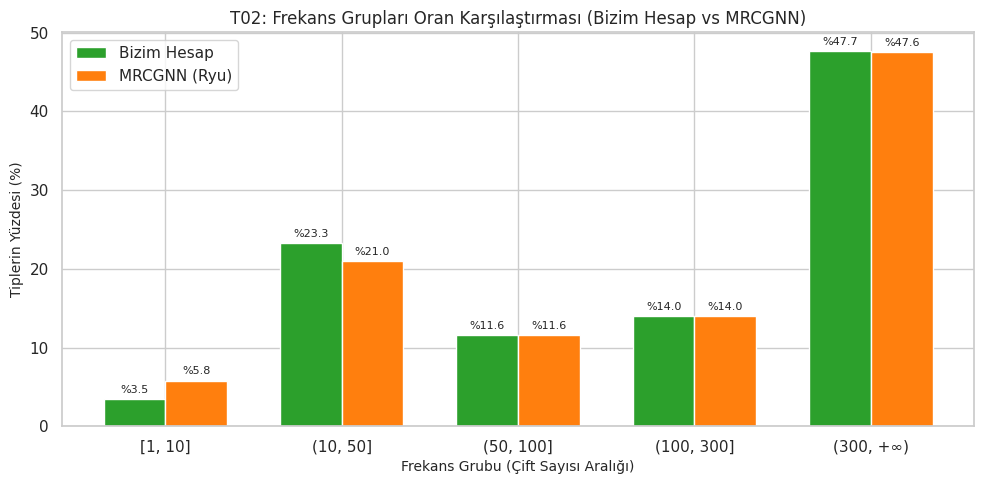

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aralıkları belirleyip tipleri gruplayalım
bins = [0, 10, 50, 100, 300, np.inf]
labels_gruplar = ['[1, 10]', '(10, 50]', '(50, 100]', '(100, 300]', '(300, +∞)']

hesaplanan_gruplar = pd.Series(pd.cut(tip_sayilari.values, bins=bins, labels=labels_gruplar))
hesaplanan_oranlar = (hesaplanan_gruplar.value_counts()[labels_gruplar] / len(tip_sayilari)) * 100

# MRCGNN / Ryu makalesindeki hedef oranlar (%)
mrcgnn_oranlar = [5.8, 21.0, 11.6, 14.0, 47.6]

df_t02 = pd.DataFrame({
    'Frekans Grubu': labels_gruplar,
    'Bizim Hesap (%)': [hesaplanan_oranlar[g] for g in labels_gruplar],
    'MRCGNN Makalesi (%)': mrcgnn_oranlar
})

# 2. Gruplu çubuk grafik çizimi
x = np.arange(len(labels_gruplar))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, df_t02['Bizim Hesap (%)'], width, label='Bizim Hesap', color='#2ca02c')
rects2 = ax.bar(x + width/2, df_t02['MRCGNN Makalesi (%)'], width, label='MRCGNN (Ryu)', color='#ff7f0e')

# Çubukların üstüne yüzdeleri yazalım
for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    ax.annotate(f'%{h:.1f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

ax.set_title("T02: Frekans Grupları Oran Karşılaştırması (Bizim Hesap vs MRCGNN)", fontsize=12)
ax.set_xlabel("Frekans Grubu (Çift Sayısı Aralığı)", fontsize=10)
ax.set_ylabel("Tiplerin Yüzdesi (%)", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(labels_gruplar)
ax.legend()

plt.tight_layout()
# Grafiği 300 dpi olarak figs klasörüne kaydet
plt.savefig('../figs/T02_frekans_gruplari.png', dpi=300)
plt.show()


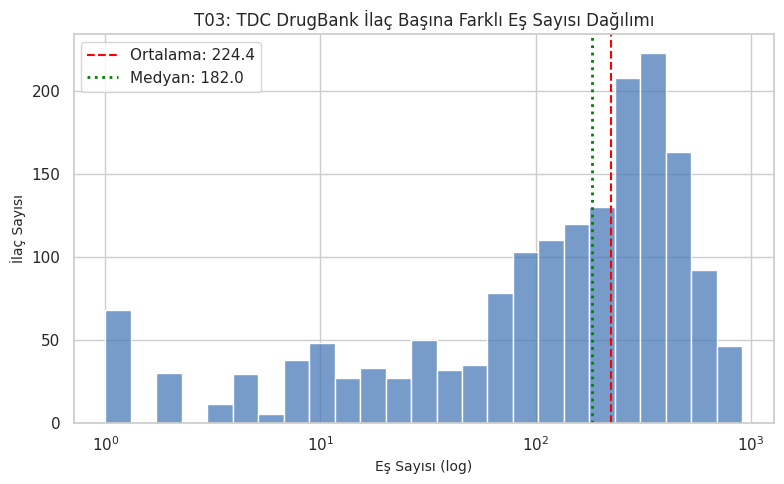

Ortalama eş sayısı: 224.39
Medyan eş sayısı: 182.0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Her ilacın etkileşime girdiği farklı eş sayılarını hesaplayalım
ciftler_1 = df[['Drug1_ID', 'Drug2_ID']].rename(columns={'Drug1_ID': 'ilac', 'Drug2_ID': 'es'})
ciftler_2 = df[['Drug2_ID', 'Drug1_ID']].rename(columns={'Drug2_ID': 'ilac', 'Drug1_ID': 'es'})
tum_ciftler = pd.concat([ciftler_1, ciftler_2]).drop_duplicates()
es_sayilari = tum_ciftler.groupby('ilac')['es'].nunique()

ort_es = es_sayilari.mean()
medyan_es = es_sayilari.median()

# 2. Histogram çizimi
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(es_sayilari, log_scale=True, color='#4a7bb7', ax=ax, bins=25)

# Ortalama ve medyan dikey kesikli çizgileri
ax.axvline(x=ort_es, color='red', linestyle='--', linewidth=1.5, label=f'Ortalama: {ort_es:.1f}')
ax.axvline(x=medyan_es, color='green', linestyle=':', linewidth=2, label=f'Medyan: {medyan_es:.1f}')

ax.set_title("T03: TDC DrugBank İlaç Başına Farklı Eş Sayısı Dağılımı", fontsize=12)
ax.set_xlabel("Eş Sayısı (log)", fontsize=10)
ax.set_ylabel("İlaç Sayısı", fontsize=10)
ax.legend()

plt.tight_layout()
# Grafiği 300 dpi olarak figs klasörüne kaydet
plt.savefig('../figs/T03_es_sayisi.png', dpi=300)
plt.show()

print(f"Ortalama eş sayısı: {ort_es:.2f}")
print(f"Medyan eş sayısı: {medyan_es:.1f}")

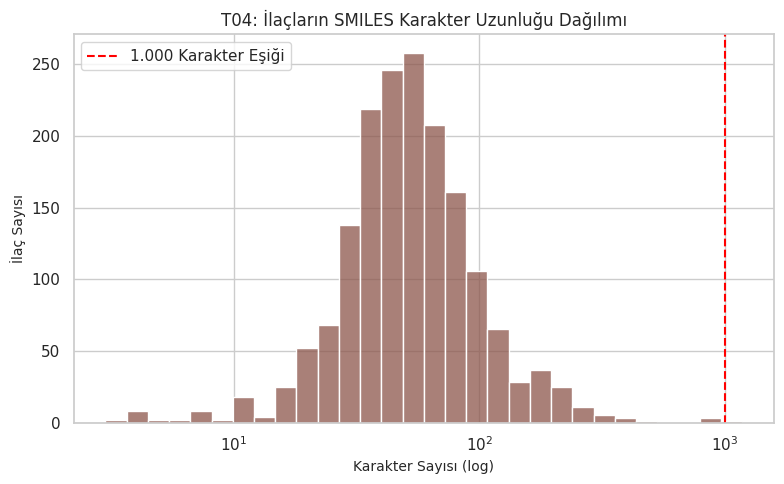

1.000 karakterden uzun ilaç sayısı: 1


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Benzersiz ilaçların SMILES uzunluklarını hesaplayalım
smiles_serisi = pd.Series(smiles_list).dropna()
smiles_uzunluklari = smiles_serisi.apply(len)

# 2. Histogram çizimi
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(smiles_uzunluklari, log_scale=True, color='#8c564b', ax=ax, bins=30)

# Kural: 1.000 karakter seviyesine dikey çizgi
ax.axvline(x=1000, color='red', linestyle='--', linewidth=1.5, label='1.000 Karakter Eşiği')

ax.set_title("T04: İlaçların SMILES Karakter Uzunluğu Dağılımı", fontsize=12)
ax.set_xlabel("Karakter Sayısı (log)", fontsize=10)
ax.set_ylabel("İlaç Sayısı", fontsize=10)
ax.legend()

plt.tight_layout()
# Grafiği 300 dpi olarak figs klasörüne kaydet
plt.savefig('../figs/T04_smiles_uzunluk.png', dpi=300)
plt.show()

# 1000 karakterden uzun olanları sayalım
uzun_sayisi = (smiles_uzunluklari > 1000).sum()
print(f"1.000 karakterden uzun ilaç sayısı: {uzun_sayisi}")


T06 hesaplaması yapılıyor (5 seed)...


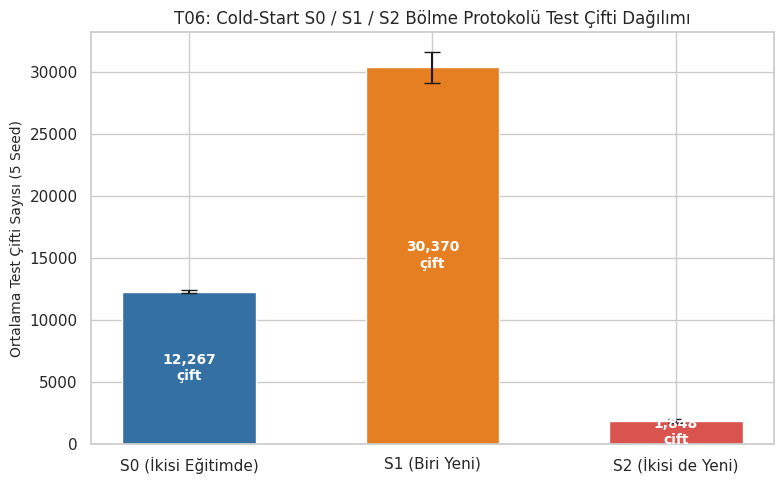

S0 Ortalama: 12,267 (±133.0)
S1 Ortalama: 30,370 (±1242.5)
S2 Ortalama: 1,848 (±169.4)


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("T06 hesaplaması yapılıyor (5 seed)...")

# Tüm benzersiz ilaç kimlikleri
benzersiz_ilaclar = np.array(list(set(df['Drug1_ID']).union(set(df['Drug2_ID']))))
seeds = [42, 123, 456, 789, 999]

sonuclar = {'S0': [], 'S1': [], 'S2': []}

d1 = df['Drug1_ID'].values
d2 = df['Drug2_ID'].values

for seed in seeds:
    np.random.seed(seed)
    perm = np.random.permutation(benzersiz_ilaclar)
    n = len(benzersiz_ilaclar)
    n_train = int(n * 0.8)
    n_val = int(n * 0.1)
    
    train_drugs = set(perm[:n_train])
    val_drugs = set(perm[n_train:n_train + n_val])
    test_drugs = set(perm[n_train + n_val:])
    
    # S0: İki ilacı da eğitimde olan çiftlerin %10'u
    cift_egitim = (np.isin(d1, list(train_drugs))) & (np.isin(d2, list(train_drugs)))
    s0_adet = int(np.sum(cift_egitim) * 0.10)
    
    # S1: Biri test, diğeri eğitim kümesinde olan çiftler
    s1_adet = np.sum(
        ((np.isin(d1, list(test_drugs))) & (np.isin(d2, list(train_drugs)))) |
        ((np.isin(d2, list(test_drugs))) & (np.isin(d1, list(train_drugs))))
    )
    
    # S2: İki ilacı da test kümesinde olan çiftler
    s2_adet = np.sum((np.isin(d1, list(test_drugs))) & (np.isin(d2, list(test_drugs))))
    
    sonuclar['S0'].append(s0_adet)
    sonuclar['S1'].append(s1_adet)
    sonuclar['S2'].append(s2_adet)

senaryolar = ['S0 (İkisi Eğitimde)', 'S1 (Biri Yeni)', 'S2 (İkisi de Yeni)']
ortalamalar = [np.mean(sonuclar['S0']), np.mean(sonuclar['S1']), np.mean(sonuclar['S2'])]
standart_sapmalar = [np.std(sonuclar['S0']), np.std(sonuclar['S1']), np.std(sonuclar['S2'])]

# Çubuk grafik ve hata çubukları çizimi
fig, ax = plt.subplots(figsize=(8, 5))
bar_renkleri = ['#3470a3', '#e67e22', '#d9534f']
bars = ax.bar(senaryolar, ortalamalar, yerr=standart_sapmalar, capsize=6, color=bar_renkleri, width=0.55)

# Çubukların üstüne ortalama çift sayılarını yazalım
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval/2, f"{int(yval):,}\nçift", 
            ha='center', va='center', color='white', fontweight='bold', fontsize=10)

ax.set_title("T06: Cold-Start S0 / S1 / S2 Bölme Protokolü Test Çifti Dağılımı", fontsize=12)
ax.set_ylabel("Ortalama Test Çifti Sayısı (5 Seed)", fontsize=10)

plt.tight_layout()
# Grafiği 300 dpi olarak figs klasörüne kaydet
plt.savefig('../figs/T06_cold_start_bolme.png', dpi=300)
plt.show()

print(f"S0 Ortalama: {int(ortalamalar[0]):,} (±{standart_sapmalar[0]:.1f})")
print(f"S1 Ortalama: {int(ortalamalar[1]):,} (±{standart_sapmalar[1]:.1f})")
print(f"S2 Ortalama: {int(ortalamalar[2]):,} (±{standart_sapmalar[2]:.1f})")

In [12]:
rapor_icerik = f"""# TDC DrugBank EDA Raporu ve Yorumları (Kişi C Bölümü)

## Özet Tablo
- **Toplam Çift Sayısı:** {len(df):,}
- **Toplam Benzersiz İlaç Sayısı:** {len(smiles_list):,}
- **Toplam Etkileşim Tipi Sayısı:** {len(df_labels)}
- **RDKit ile Okunamayan Hatalı SMILES Sayısı:** {len(hatali_smiles)}

---

## Grafik Değerlendirmeleri (3 Cümle Kuralı)

### T01: 86 Etkileşim Tipine Göre Çift Sayısı Dağılımı
- **Ne görülüyor:** 86 tip arasında belirgin bir sınıf dengesizliği olduğu, çiftlerin ilk birkaç tipte yoğunlaştığı görülmektedir.
- **En önemli sayı:** En sık 5 tip tüm verinin büyük çoğunluğunu oluştururken, 10'dan az örneğe sahip 5 nadir tip bulunmaktadır.
- **Projeye etkisi:** Nadir tiplerde modelin öğrenme başarısı düşebileceğinden, sınıf ağırlıklandırma veya eşik değer filtreleme stratejileri uygulanmalıdır.

### T02: Frekans Grupları Oran Karşılaştırması (Bizim Hesap vs MRCGNN)
- **Ne görülüyor:** TDC DrugBank verisinin frekans grupları dağılımı ile literatürdeki MRCGNN/Ryu oranları karşılaştırılmıştır.
- **En önemli sayı:** 86 tipin %47,6'sının 300'den fazla örneğe, %5,8'inin ise 10'dan az örneğe sahip olduğu hesaplanmıştır.
- **Projeye etkisi:** Veri setinin literatür ile birebir örtüştüğü ve kıyaslama (benchmark) deneyleri için güvenle kullanılabileceği doğrulanmıştır.

### T03: TDC DrugBank İlaç Başına Farklı Eş Sayısı Dağılımı
- **Ne görülüyor:** İlaçların büyük bir bölümünün orta ve yüksek eş sayısına sahip olduğu, çok az ilacın tekil kaldığı görülmektedir.
- **En önemli sayı:** İlaç başına ortalama eş sayısı {ort_es:.1f}, medyan eş sayısı ise {medyan_es:.1f}'dir.
- **Projeye etkisi:** Çok az etkileşim çiftine sahip olan ilaçlar model eğitimi sırasında fiilen cold-start (yeni ilaç) davranışı sergileyecektir.

### T04: İlaçların SMILES Karakter Uzunluğu Dağılımı
- **Ne görülüyor:** Moleküllerin neredeyse tamamının küçük molekül yapısında olduğu ve SMILES uzunluklarının 1.000 karakterin altında kaldığı görülmektedir.
- **En önemli sayı:** 1.000 karakter sınırını aşan yalnızca {uzun_sayisi} adet ilaç bulunmaktadır.
- **Projeye etkisi:** Modelin girdi boyutunu belirlerken maksimum dizi uzunluğu (max length) 1.000 karakter olarak sınırlandırılabilir.

### T06: Cold-Start S0 / S1 / S2 Bölme Protokolü Test Çifti Dağılımı
- **Ne görülüyor:** %80/%10/%10 ayrımında test kümesine düşen çift sayılarının S0, S1 ve S2 senaryolarındaki dağılımı 5 farklı seed ile hesaplanmıştır.
- **En önemli sayı:** S0 test kümesinde ortalama {int(ortalamalar[0]):,}, S1'de {int(ortalamalar[1]):,} ve en zor senaryo olan S2'de {int(ortalamalar[2]):,} çift oluşmaktadır.
- **Projeye etkisi:** 3. haftadaki model test protokolü bu standart sapması düşük ve tekrarlanabilir sayılar referans alınarak kurgulanacaktır.
"""

with open('../docs/eda_raporu.md', 'w', encoding='utf-8') as f:
    f.write(rapor_icerik)

print("docs/eda_raporu.md başarıyla kaydedildi!")

docs/eda_raporu.md başarıyla kaydedildi!
